In [1]:
import sys
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Librosa:", librosa.__version__)


/home/adminbum/ntqai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /home/adminbum/ntqai/.venv/bin/python
NumPy: 2.5.3
Pandas: 3.0.6
Librosa: 1.0.0


In [2]:
DATASET_PATH = Path("/mnt/d/Data/VNTM3")
AUDIT_DIR = DATASET_PATH / "_audit"
AUDIT_CSV = AUDIT_DIR / "audio_audit.csv"

OUTPUT_DIR = DATASET_PATH / "_split_v1"
OUTPUT_DIR.mkdir(exist_ok=True)




TARGET_SR = 22050
N_MELS = 64
N_FFT = 2048
HOP_LENGTH = 512




N_TIME_BLOCKS = 12






AUTO_GROUP_THRESHOLD = 0.985


REVIEW_THRESHOLD = 0.950


TOP_K = 8




TRAIN_RATIO = 0.70
VALID_RATIO = 0.15
TEST_RATIO = 0.15

RANDOM_SEED = 42

print("Dataset:", DATASET_PATH)
print("Audit:", AUDIT_CSV)
print("Output:", OUTPUT_DIR)

if not AUDIT_CSV.exists():
    raise FileNotFoundError(
        f"Không tìm thấy {AUDIT_CSV}. Hãy chạy Notebook 01 trước."
    )


Dataset: /mnt/d/Data/VNTM3
Audit: /mnt/d/Data/VNTM3/_audit/audio_audit.csv
Output: /mnt/d/Data/VNTM3/_split_v1


In [3]:
df = pd.read_csv(AUDIT_CSV)

print("Rows in audit:", len(df))
print("\nClasses:")
display(df.groupby("label").size().rename("files").reset_index())

df = df[df["status"] == "OK"].copy().reset_index(drop=True)

print("\nUsable after removing read errors:", len(df))


Rows in audit: 2499

Classes:


,label,files
0,cailuong,500
1,catru,499
2,chauvan,500
3,cheo,500
4,hatxam,500



Usable after removing read errors: 2499


In [4]:
df["exact_duplicate_removed"] = False
df["exact_duplicate_of"] = ""

if "sha256" not in df.columns:
    raise RuntimeError(
        "audio_audit.csv không có cột sha256. "
        "Hãy chạy hết Notebook 01 trước."
    )

for sha, part in df[df["sha256"].notna()].groupby("sha256"):
    if len(part) <= 1:
        continue

    
    part = part.sort_values(["label", "filename"])
    keeper_idx = part.index[0]
    keeper_path = df.loc[keeper_idx, "relative_path"]

    for idx in part.index[1:]:
        df.loc[idx, "exact_duplicate_removed"] = True
        df.loc[idx, "exact_duplicate_of"] = keeper_path

exact_removed = df[df["exact_duplicate_removed"]].copy()

print("Exact duplicate files removed from manifest:", len(exact_removed))

if len(exact_removed):
    display(
        exact_removed[
            ["label", "filename", "relative_path", "exact_duplicate_of"]
        ]
    )

work_df = df[~df["exact_duplicate_removed"]].copy().reset_index(drop=True)

print("Files entering fingerprint stage:", len(work_df))


Exact duplicate files removed from manifest: 4


,label,filename,relative_path,exact_duplicate_of
870,catru,Catru.371.wav,catru/Catru.371.wav,catru/Catru.370.wav
976,catru,Catru.477.wav,catru/Catru.477.wav,catru/Catru.476.wav
990,catru,Catru.491.wav,catru/Catru.491.wav,catru/Catru.490.wav
1358,chauvan,Chauvan.359.wav,chauvan/Chauvan.359.wav,chauvan/Chauvan.358.wav


Files entering fingerprint stage: 2495


In [5]:
def extract_numeric_index(filename):
    nums = re.findall(r"\d+", Path(filename).stem)
    return int(nums[-1]) if nums else np.nan

work_df["file_index"] = work_df["filename"].apply(extract_numeric_index)

display(
    work_df[["label", "filename", "file_index"]].head(15)
)


,label,filename,file_index
0,cailuong,CaiLuong.000.wav,0
1,cailuong,CaiLuong.001.wav,1
2,cailuong,CaiLuong.002.wav,2
3,cailuong,CaiLuong.003.wav,3
4,cailuong,CaiLuong.004.wav,4
5,cailuong,CaiLuong.005.wav,5
6,cailuong,CaiLuong.006.wav,6
7,cailuong,CaiLuong.007.wav,7
8,cailuong,CaiLuong.008.wav,8
9,cailuong,CaiLuong.009.wav,9


In [6]:
def block_stats(matrix, n_blocks=12):
    
    chunks = np.array_split(matrix, n_blocks, axis=1)
    feats = []

    for c in chunks:
        if c.shape[1] == 0:
            mean = np.zeros(matrix.shape[0], dtype=np.float32)
            std = np.zeros(matrix.shape[0], dtype=np.float32)
        else:
            mean = np.mean(c, axis=1)
            std = np.std(c, axis=1)

        feats.extend([mean, std])

    return np.concatenate(feats).astype(np.float32)


def make_fingerprint(path):
    y, sr = librosa.load(
        path,
        sr=TARGET_SR,
        mono=True
    )

    
    y = y - np.mean(y)

    
    peak = np.max(np.abs(y))
    if peak > 1e-8:
        y = y / peak

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    logmel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    
    logmel = np.clip(logmel, -80.0, 0.0) / 80.0

    fp = block_stats(logmel, N_TIME_BLOCKS)

    norm = np.linalg.norm(fp)
    if norm > 1e-8:
        fp = fp / norm

    return fp


fingerprints = []
failed = []

for row in tqdm(
    work_df.itertuples(index=False),
    total=len(work_df),
    desc="Extracting fingerprints"
):
    try:
        fp = make_fingerprint(row.path)
        fingerprints.append(fp)
        failed.append("")
    except Exception as e:
        fingerprints.append(None)
        failed.append(repr(e))

work_df["fingerprint_error"] = failed

valid_mask = work_df["fingerprint_error"].eq("")

print("Fingerprint OK:", int(valid_mask.sum()))
print("Fingerprint errors:", int((~valid_mask).sum()))

if (~valid_mask).any():
    display(
        work_df.loc[
            ~valid_mask,
            ["label", "filename", "path", "fingerprint_error"]
        ]
    )


Extracting fingerprints: 100%|██████████| 2495/2495 [02:17<00:00, 18.17it/s]

Fingerprint OK: 2495
Fingerprint errors: 0


In [7]:
valid_df = work_df[valid_mask].copy().reset_index(drop=True)

X = np.stack([
    fingerprints[i]
    for i in np.flatnonzero(valid_mask.to_numpy())
])

X = normalize(X, norm="l2")

pair_records = []

for label in tqdm(
    sorted(valid_df["label"].unique()),
    desc="Nearest-neighbor search"
):
    idx = np.flatnonzero(valid_df["label"].to_numpy() == label)
    Xc = X[idx]

    n_neighbors = min(TOP_K + 1, len(idx))

    nn = NearestNeighbors(
        n_neighbors=n_neighbors,
        metric="cosine",
        algorithm="brute"
    )
    nn.fit(Xc)

    distances, neighbors = nn.kneighbors(Xc)

    for local_i in range(len(idx)):
        global_i = idx[local_i]

        for rank in range(1, n_neighbors):
            local_j = neighbors[local_i, rank]
            global_j = idx[local_j]

            if global_i >= global_j:
                continue

            similarity = 1.0 - float(distances[local_i, rank])

            if similarity >= REVIEW_THRESHOLD:
                a = valid_df.iloc[global_i]
                b = valid_df.iloc[global_j]

                pair_records.append({
                    "label": label,
                    "file_a": a["filename"],
                    "file_b": b["filename"],
                    "path_a": a["relative_path"],
                    "path_b": b["relative_path"],
                    "index_a": a["file_index"],
                    "index_b": b["file_index"],
                    "index_gap": (
                        abs(a["file_index"] - b["file_index"])
                        if pd.notna(a["file_index"]) and pd.notna(b["file_index"])
                        else np.nan
                    ),
                    "similarity": similarity,
                    "auto_group": similarity >= AUTO_GROUP_THRESHOLD
                })

pairs_df = pd.DataFrame(pair_records)

if len(pairs_df):
    pairs_df = (
        pairs_df
        .drop_duplicates(subset=["path_a", "path_b"])
        .sort_values("similarity", ascending=False)
        .reset_index(drop=True)
    )

print("Pairs >= review threshold:", len(pairs_df))

if len(pairs_df):
    display(pairs_df.head(50))
else:
    print("Không có pair nào vượt REVIEW_THRESHOLD.")


Nearest-neighbor search: 100%|██████████| 5/5 [00:00<00:00,  5.68it/s]

Pairs >= review threshold: 10392


,label,file_a,file_b,path_a,path_b,index_a,index_b,index_gap,similarity,auto_group
0,cheo,Cheo.106.wav,Cheo.193.wav,cheo/Cheo.106.wav,cheo/Cheo.193.wav,106,193,87,0.998225,True
1,cheo,Cheo.423.wav,Cheo.425.wav,cheo/Cheo.423.wav,cheo/Cheo.425.wav,423,425,2,0.998129,True
2,cheo,Cheo.082.wav,Cheo.499.wav,cheo/Cheo.082.wav,cheo/Cheo.499.wav,82,499,417,0.997587,True
3,hatxam,Xam.356.wav,Xam.357.wav,hatxam/Xam.356.wav,hatxam/Xam.357.wav,356,357,1,0.997576,True
4,hatxam,Xam.080.wav,Xam.092.wav,hatxam/Xam.080.wav,hatxam/Xam.092.wav,80,92,12,0.997510,True
5,cheo,Cheo.113.wav,Cheo.193.wav,cheo/Cheo.113.wav,cheo/Cheo.193.wav,113,193,80,0.997494,True
6,cheo,Cheo.082.wav,Cheo.171.wav,cheo/Cheo.082.wav,cheo/Cheo.171.wav,82,171,89,0.997477,True
7,cheo,Cheo.106.wav,Cheo.113.wav,cheo/Cheo.106.wav,cheo/Cheo.113.wav,106,113,7,0.997376,True
8,hatxam,Xam.220.wav,Xam.225.wav,hatxam/Xam.220.wav,hatxam/Xam.225.wav,220,225,5,0.997375,True
9,cheo,Cheo.171.wav,Cheo.499.wav,cheo/Cheo.171.wav,cheo/Cheo.499.wav,171,499,328,0.997312,True


In [8]:

path_to_i = {
    row.relative_path: i
    for i, row in enumerate(valid_df.itertuples(index=False))
}

adjacent_records = []

for label, part in valid_df.groupby("label"):
    part = part[pd.notna(part["file_index"])].sort_values("file_index")

    rows = list(part.itertuples(index=False))

    for a, b in zip(rows[:-1], rows[1:]):
        if int(b.file_index) - int(a.file_index) != 1:
            continue

        ia = path_to_i[a.relative_path]
        ib = path_to_i[b.relative_path]

        sim = float(np.dot(X[ia], X[ib]))

        adjacent_records.append({
            "label": label,
            "file_a": a.filename,
            "file_b": b.filename,
            "index_a": int(a.file_index),
            "index_b": int(b.file_index),
            "similarity": sim
        })

adjacent_df = pd.DataFrame(adjacent_records)

print("Adjacent-number pairs:", len(adjacent_df))

if len(adjacent_df):
    display(
        adjacent_df.groupby("label")["similarity"]
        .agg(["count", "mean", "std", "min", "median", "max"])
        .round(4)
    )

    display(
        adjacent_df
        .sort_values("similarity", ascending=False)
        .head(50)
    )


Adjacent-number pairs: 2485


,count,mean,std,min,median,max
label,,,,,,
cailuong,499,0.9797,0.0108,0.9268,0.9822,0.9950
catru,491,0.9766,0.0103,0.9242,0.9778,0.9955
chauvan,497,0.9829,0.0085,0.9066,0.9848,0.9945
cheo,499,0.9831,0.0130,0.8972,0.9878,0.9958
hatxam,499,0.9832,0.0098,0.9344,0.9858,0.9976


,label,file_a,file_b,index_a,index_b,similarity
2342,hatxam,Xam.356.wav,Xam.357.wav,356,357,0.997576
2206,hatxam,Xam.220.wav,Xam.221.wav,220,221,0.995962
1701,cheo,Cheo.214.wav,Cheo.215.wav,214,215,0.995848
1488,cheo,Cheo.001.wav,Cheo.002.wav,1,2,0.995756
2437,hatxam,Xam.451.wav,Xam.452.wav,451,452,0.995693
636,catru,Catru.139.wav,Catru.140.wav,139,140,0.995538
2433,hatxam,Xam.447.wav,Xam.448.wav,447,448,0.995511
1490,cheo,Cheo.003.wav,Cheo.004.wav,3,4,0.995510
2336,hatxam,Xam.350.wav,Xam.351.wav,350,351,0.995492
635,catru,Catru.138.wav,Catru.139.wav,138,139,0.995391


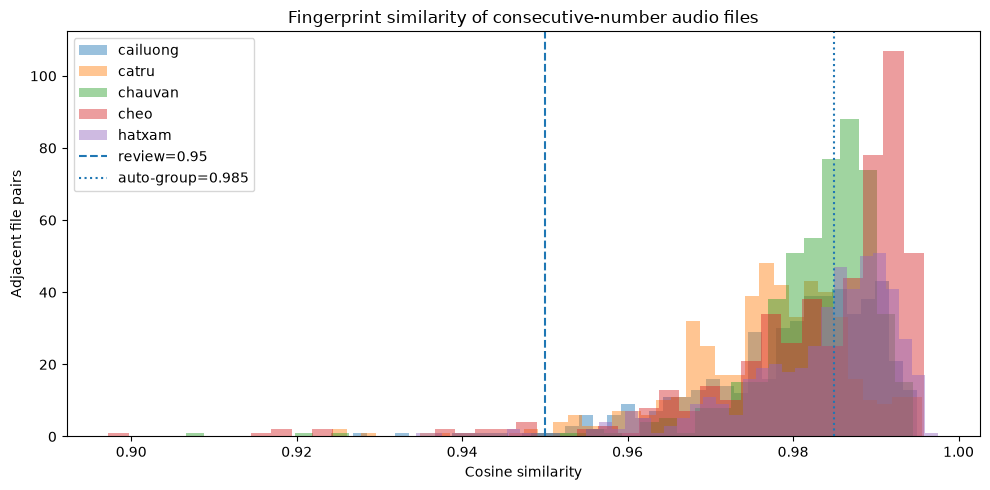

In [9]:
if len(adjacent_df):
    plt.figure(figsize=(10, 5))

    for label, part in adjacent_df.groupby("label"):
        plt.hist(
            part["similarity"],
            bins=40,
            alpha=0.45,
            label=label
        )

    plt.axvline(
        REVIEW_THRESHOLD,
        linestyle="--",
        label=f"review={REVIEW_THRESHOLD}"
    )
    plt.axvline(
        AUTO_GROUP_THRESHOLD,
        linestyle=":",
        label=f"auto-group={AUTO_GROUP_THRESHOLD}"
    )

    plt.xlabel("Cosine similarity")
    plt.ylabel("Adjacent file pairs")
    plt.title("Fingerprint similarity of consecutive-number audio files")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [10]:
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra = self.find(a)
        rb = self.find(b)

        if ra == rb:
            return

        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra

        self.parent[rb] = ra

        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1


uf = UnionFind(len(valid_df))

relpath_to_idx = {
    row.relative_path: i
    for i, row in enumerate(valid_df.itertuples(index=False))
}

if len(pairs_df):
    auto_pairs = pairs_df[pairs_df["auto_group"] == True]

    for row in auto_pairs.itertuples(index=False):
        ia = relpath_to_idx[row.path_a]
        ib = relpath_to_idx[row.path_b]
        uf.union(ia, ib)

roots = [uf.find(i) for i in range(len(valid_df))]


root_to_gid = {}
class_counter = {}

group_ids = []

for i, root in enumerate(roots):
    label = valid_df.loc[i, "label"]

    key = (label, root)

    if key not in root_to_gid:
        class_counter[label] = class_counter.get(label, 0) + 1
        root_to_gid[key] = f"{label}_G{class_counter[label]:04d}"

    group_ids.append(root_to_gid[key])

valid_df["group_id"] = group_ids

group_summary = (
    valid_df.groupby(["label", "group_id"])
    .size()
    .rename("n_files")
    .reset_index()
)

print("Total groups:", valid_df["group_id"].nunique())
print("Groups with >1 file:", int((group_summary["n_files"] > 1).sum()))

display(
    group_summary[
        group_summary["n_files"] > 1
    ].sort_values(
        ["n_files", "label"],
        ascending=[False, True]
    ).head(100)
)


Total groups: 414
Groups with >1 file: 23


,label,group_id,n_files
239,chauvan,chauvan_G0002,458
280,cheo,cheo_G0001,441
339,hatxam,hatxam_G0002,414
129,catru,catru_G0003,380
4,cailuong,cailuong_G0005,348
96,cailuong,cailuong_G0097,21
365,hatxam,hatxam_G0028,6
108,cailuong,cailuong_G0109,5
378,hatxam,hatxam_G0041,3
16,cailuong,cailuong_G0017,2


In [11]:
rng = np.random.default_rng(RANDOM_SEED)

split_map = {}

for label, class_groups in group_summary.groupby("label"):

    groups = class_groups.copy()

    
    groups["tie"] = rng.random(len(groups))
    groups = groups.sort_values(
        ["n_files", "tie"],
        ascending=[False, True]
    )

    total = int(groups["n_files"].sum())

    targets = {
        "train": total * TRAIN_RATIO,
        "valid": total * VALID_RATIO,
        "test": total * TEST_RATIO,
    }

    counts = {
        "train": 0,
        "valid": 0,
        "test": 0,
    }

    for row in groups.itertuples(index=False):

        
        deficits = {
            s: (targets[s] - counts[s]) / max(targets[s], 1)
            for s in counts
        }

        chosen = max(deficits, key=deficits.get)

        split_map[row.group_id] = chosen
        counts[chosen] += int(row.n_files)

valid_df["split"] = valid_df["group_id"].map(split_map)

print("Split counts:")
display(
    valid_df.groupby(["label", "split"])
    .size()
    .unstack(fill_value=0)
)

print("\nSplit percentages:")
split_counts = valid_df["split"].value_counts()
display(
    (100 * split_counts / len(valid_df))
    .round(2)
    .rename("percent")
)


Split counts:


split,test,train,valid
label,,,
cailuong,75,350,75
catru,58,380,58
chauvan,20,458,21
cheo,29,441,30
hatxam,43,414,43



Split percentages:


split
train    81.88
valid     9.10
test      9.02
Name: percent, dtype: float64

In [12]:

group_split_n = valid_df.groupby("group_id")["split"].nunique()
leaking_groups = group_split_n[group_split_n > 1]

assert len(leaking_groups) == 0, (
    f"ERROR: {len(leaking_groups)} groups leak across splits."
)


assert not valid_df["relative_path"].duplicated().any(), (
    "ERROR: duplicate relative_path in manifest."
)


removed_paths = set(exact_removed["relative_path"])
final_paths = set(valid_df["relative_path"])

assert not (removed_paths & final_paths), (
    "ERROR: removed exact duplicate still appears in final manifest."
)

print("✅ No group leakage")
print("✅ No duplicate paths")
print("✅ Exact duplicate copies excluded")


✅ No group leakage
✅ No duplicate paths
✅ Exact duplicate copies excluded


In [13]:
split_by_path = dict(
    zip(valid_df["relative_path"], valid_df["split"])
)

cross_records = []

if len(pairs_df):
    for row in pairs_df.itertuples(index=False):
        sa = split_by_path.get(row.path_a)
        sb = split_by_path.get(row.path_b)

        if sa is not None and sb is not None and sa != sb:
            cross_records.append({
                "label": row.label,
                "file_a": row.file_a,
                "file_b": row.file_b,
                "similarity": row.similarity,
                "split_a": sa,
                "split_b": sb,
                "auto_group": row.auto_group,
            })

cross_split_df = pd.DataFrame(cross_records)

print("Similar pairs crossing split:", len(cross_split_df))

if len(cross_split_df):
    display(
        cross_split_df
        .sort_values("similarity", ascending=False)
        .head(100)
    )

    dangerous = cross_split_df[
        cross_split_df["similarity"] >= AUTO_GROUP_THRESHOLD
    ]

    print(
        "Pairs >= AUTO_GROUP_THRESHOLD crossing split:",
        len(dangerous)
    )

    assert len(dangerous) == 0, (
        "ERROR: auto-group-level similar pair crosses split."
    )
else:
    print("✅ No reviewed similar pairs cross split.")


Similar pairs crossing split: 1625


,label,file_a,file_b,similarity,split_a,split_b,auto_group
0,catru,Catru.006.wav,Catru.211.wav,0.984989,train,valid,False
1,catru,Catru.338.wav,Catru.339.wav,0.984984,test,train,False
2,cailuong,CaiLuong.085.wav,CaiLuong.352.wav,0.984980,train,test,False
3,cailuong,CaiLuong.073.wav,CaiLuong.122.wav,0.984976,test,train,False
4,cheo,Cheo.017.wav,Cheo.397.wav,0.984975,valid,train,False
...,...,...,...,...,...,...,...
95,cailuong,CaiLuong.056.wav,CaiLuong.499.wav,0.984175,valid,test,False
96,catru,Catru.292.wav,Catru.467.wav,0.984146,test,train,False
97,cheo,Cheo.012.wav,Cheo.061.wav,0.984143,valid,train,False
98,chauvan,Chauvan.025.wav,Chauvan.361.wav,0.984134,test,train,False


Pairs >= AUTO_GROUP_THRESHOLD crossing split: 0


In [14]:
manifest_cols = [
    "label",
    "filename",
    "relative_path",
    "path",
    "duration_sec",
    "sample_rate",
    "channels",
    "rms",
    "sha256",
    "file_index",
    "group_id",
    "split",
]

manifest = valid_df[manifest_cols].copy()

manifest.to_csv(
    OUTPUT_DIR / "manifest_all.csv",
    index=False,
    encoding="utf-8-sig"
)

for split_name in ["train", "valid", "test"]:
    manifest[
        manifest["split"] == split_name
    ].to_csv(
        OUTPUT_DIR / f"{split_name}.csv",
        index=False,
        encoding="utf-8-sig"
    )

pairs_df.to_csv(
    OUTPUT_DIR / "near_duplicate_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

cross_split_df.to_csv(
    OUTPUT_DIR / "cross_split_review.csv",
    index=False,
    encoding="utf-8-sig"
)

adjacent_df.to_csv(
    OUTPUT_DIR / "adjacent_similarity.csv",
    index=False,
    encoding="utf-8-sig"
)

group_summary.to_csv(
    OUTPUT_DIR / "group_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

exact_removed.to_csv(
    OUTPUT_DIR / "exact_duplicates_removed.csv",
    index=False,
    encoding="utf-8-sig"
)

split_summary = (
    manifest.groupby(["split", "label"])
    .size()
    .rename("n_files")
    .reset_index()
)

split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved reports to:")
print(OUTPUT_DIR)

for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", p.name)


Saved reports to:
/mnt/d/Data/VNTM3/_split_v1
 - adjacent_similarity.csv
 - cross_split_review.csv
 - exact_duplicates_removed.csv
 - group_summary.csv
 - manifest_all.csv
 - near_duplicate_pairs.csv
 - split_summary.csv
 - test.csv
 - train.csv
 - valid.csv


In [15]:
print("=" * 72)
print("VNTM3 SPLIT V1 SUMMARY")
print("=" * 72)

print("Files after exact dedup :", len(manifest))
print("Classes                 :", manifest["label"].nunique())
print("Groups                  :", manifest["group_id"].nunique())
print("Multi-file groups       :", int((group_summary["n_files"] > 1).sum()))
print("Review similarity pairs :", len(pairs_df))
print("Cross-split review pairs:", len(cross_split_df))

print("\nFILES BY SPLIT / CLASS")
display(
    manifest.groupby(["label", "split"])
    .size()
    .unstack(fill_value=0)
)

print("\nTOTAL BY SPLIT")
display(
    manifest["split"]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="files")
)

print(
    "\nNEXT: gửi các CSV review cho ChatGPT trước khi tạo spectrogram."
)


VNTM3 SPLIT V1 SUMMARY
Files after exact dedup : 2495
Classes                 : 5
Groups                  : 414
Multi-file groups       : 23
Review similarity pairs : 10392
Cross-split review pairs: 1625

FILES BY SPLIT / CLASS


split,test,train,valid
label,,,
cailuong,75,350,75
catru,58,380,58
chauvan,20,458,21
cheo,29,441,30
hatxam,43,414,43



TOTAL BY SPLIT


,split,files
0,train,2043
1,valid,227
2,test,225



NEXT: gửi các CSV review cho ChatGPT trước khi tạo spectrogram.
